In [1]:
# BQ02 — Churn lớn đến đâu?
# Mục tiêu: tính baseline churn thống nhất cho toàn bộ phân tích.

from pathlib import Path
import math

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

data_candidates = [
    Path('data/cell2cell_complete_cases.csv'),
    Path('../data/cell2cell_complete_cases.csv'),
]
data_path = next((path for path in data_candidates if path.exists()), None)
if data_path is None:
    raise FileNotFoundError('Không tìm thấy data/cell2cell_complete_cases.csv')

df = pd.read_csv(data_path)
print(f'Đã đọc {len(df):,} dòng và {df.shape[1]:,} cột từ {data_path}')


Đã đọc 49,752 dòng và 58 cột từ ..\data\cell2cell_complete_cases.csv


In [2]:
# Chuẩn hóa và kiểm tra biến mục tiêu trước khi tính baseline.
target = 'Churn'
if target not in df.columns:
    raise KeyError(f'Không tìm thấy cột mục tiêu {target!r}')
if df[target].isna().any():
    raise ValueError(f'Cột {target} còn {df[target].isna().sum():,} giá trị thiếu')

if not pd.api.types.is_numeric_dtype(df[target]):
    churn_mapping = {
        'yes': 1, 'true': 1, 'churn': 1, '1': 1,
        'no': 0, 'false': 0, 'active': 0, '0': 0,
    }
    normalized_target = df[target].astype(str).str.strip().str.lower()
    unknown_labels = sorted(set(normalized_target) - set(churn_mapping))
    if unknown_labels:
        raise ValueError(f'Nhãn Churn chưa được định nghĩa: {unknown_labels}')
    df[target] = normalized_target.map(churn_mapping)

df[target] = df[target].astype(int)
valid_labels = set(df[target].unique())
if not valid_labels.issubset({0, 1}):
    raise ValueError(f'Churn phải là biến nhị phân 0/1, đang có: {sorted(valid_labels)}')

if 'CustomerID' in df.columns:
    duplicate_customers = int(df['CustomerID'].duplicated().sum())
    if duplicate_customers:
        raise ValueError(f'Có {duplicate_customers:,} CustomerID bị trùng')

print('Biến Churn hợp lệ và mỗi dòng được xem là một khách hàng đủ điều kiện.')


Biến Churn hợp lệ và mỗi dòng được xem là một khách hàng đủ điều kiện.


In [3]:
# Tính baseline churn và khoảng tin cậy Wilson 95%.
def wilson_interval(successes, observations, confidence=0.95):
    if observations <= 0:
        raise ValueError('Số quan sát phải lớn hơn 0')
    if confidence != 0.95:
        raise ValueError('Đoạn mã này đang cố định z = 1.96 cho mức tin cậy 95%')

    z = 1.96
    p_hat = successes / observations
    denominator = 1 + z**2 / observations
    centre = (p_hat + z**2 / (2 * observations)) / denominator
    margin = (
        z
        * math.sqrt(
            p_hat * (1 - p_hat) / observations
            + z**2 / (4 * observations**2)
        )
        / denominator
    )
    return centre - margin, centre + margin

eligible_customers = int(len(df))
churners = int(df[target].sum())
non_churners = eligible_customers - churners
churn_rate = churners / eligible_customers
non_churn_rate = non_churners / eligible_customers
ci_lower, ci_upper = wilson_interval(churners, eligible_customers)

assert churners + non_churners == eligible_customers
assert math.isclose(churn_rate + non_churn_rate, 1.0)

bq02_summary = pd.DataFrame({
    'KPI': [
        'Khách hàng đủ điều kiện',
        'Khách hàng churn',
        'Khách hàng không churn',
        'Baseline churn rate',
        'Cận dưới CI 95%',
        'Cận trên CI 95%',
    ],
    'Giá trị': [
        eligible_customers, churners, non_churners,
        churn_rate, ci_lower, ci_upper,
    ],
})

display(bq02_summary)
print(
    f'Baseline churn: {churn_rate:.2%} '
    f'({churners:,}/{eligible_customers:,} khách hàng); '
    f'95% CI: {ci_lower:.2%}–{ci_upper:.2%}.'
)


,KPI,Giá trị
0,Khách hàng đủ điều kiện,49752.000000
1,Khách hàng churn,14245.000000
2,Khách hàng không churn,35507.000000
3,Baseline churn rate,0.286320
4,Cận dưới CI 95%,0.282365
5,Cận trên CI 95%,0.290309


Baseline churn: 28.63% (14,245/49,752 khách hàng); 95% CI: 28.24%–29.03%.


C:\Users\Admin\AppData\Local\Temp\ipykernel_3364\3058991235.py:112: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.04, 0.06, 0.86, 0.94])


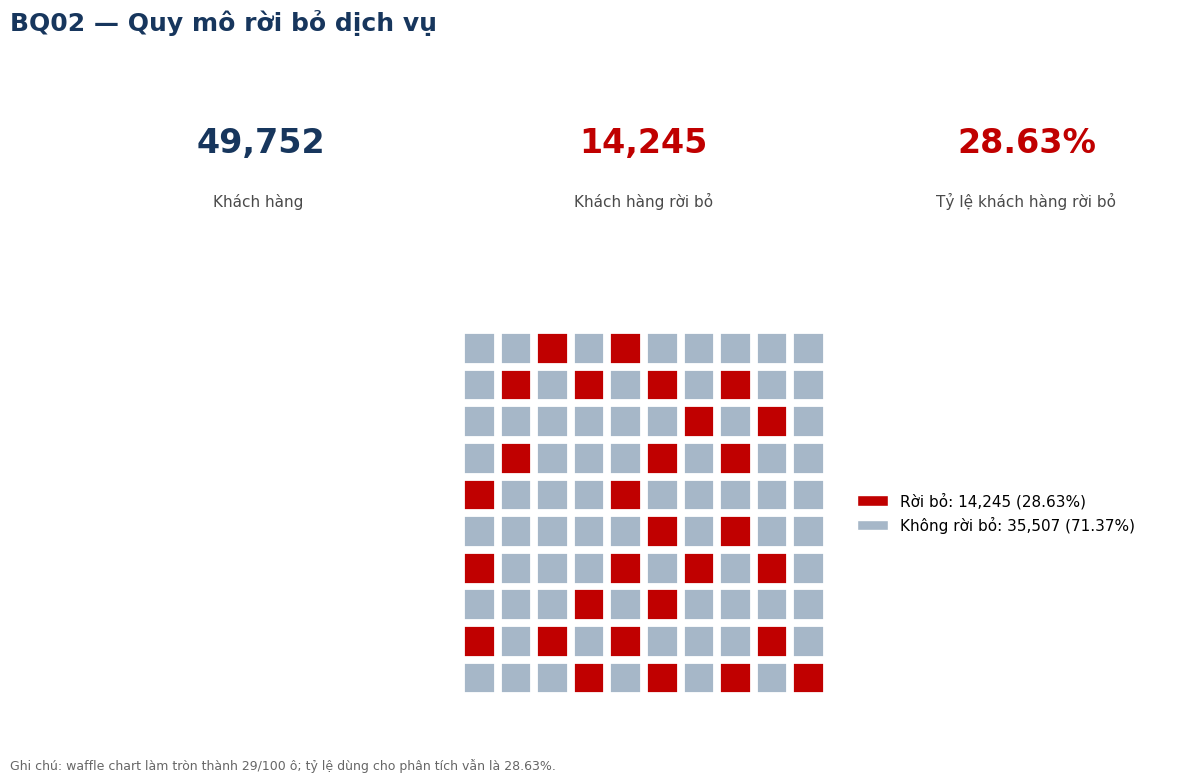

In [5]:
# C02 — KPI và waffle chart 10 × 10.
import random

# Mỗi ô đại diện xấp xỉ 1% khách hàng; số ô được làm tròn để trực quan.
total_tiles = 100
churn_tiles = round(churn_rate * total_tiles)
non_churn_tiles = total_tiles - churn_tiles

# Chọn ngẫu nhiên trên các vị trí xen kẽ để ô đỏ không dính thành một khối.
random_generator = random.Random(42)
separated_positions = [
    index
    for index in range(total_tiles)
    if ((index // 10) + (index % 10)) % 2 == 0
]

if churn_tiles <= len(separated_positions):
    churn_tile_positions = set(
        random_generator.sample(separated_positions, churn_tiles)
    )
else:
    churn_tile_positions = set(separated_positions)
    remaining_positions = [
        index for index in range(total_tiles)
        if index not in churn_tile_positions
    ]
    churn_tile_positions.update(
        random_generator.sample(
            remaining_positions, churn_tiles - len(churn_tile_positions)
        )
    )

tile_colors = [
    '#C00000' if index in churn_tile_positions else '#A6B7C8'
    for index in range(total_tiles)
]
tile_x = [index % 10 for index in range(total_tiles)]
tile_y = [9 - index // 10 for index in range(total_tiles)]

fig = plt.figure(figsize=(14, 8), facecolor='white')
grid = fig.add_gridspec(
    nrows=2,
    ncols=3,
    height_ratios=[0.8, 2.2],
    hspace=0.35,
)

kpi_specs = [
    ('Khách hàng ', f'{eligible_customers:,}', '#17365D'),
    ('Khách hàng rời bỏ', f'{churners:,}', '#C00000'),
    ('Tỷ lệ khách hàng rời bỏ', f'{churn_rate:.2%}', '#C00000'),
]

for column, (label, value, color) in enumerate(kpi_specs):
    ax_kpi = fig.add_subplot(grid[0, column])
    ax_kpi.axis('off')
    ax_kpi.text(
        0.5, 0.62, value,
        ha='center', va='center',
        fontsize=24, fontweight='bold', color=color,
    )
    ax_kpi.text(
        0.5, 0.20, label,
        ha='center', va='center',
        fontsize=11, color='#4A4A4A',
    )

ax_waffle = fig.add_subplot(grid[1, :])
ax_waffle.scatter(
    tile_x, tile_y,
    c=tile_colors,
    marker='s',
    s=520,
    edgecolors='white',
    linewidths=2,
)
ax_waffle.set_xlim(-0.75, 9.75)
ax_waffle.set_ylim(-0.75, 9.75)
ax_waffle.set_aspect('equal')
ax_waffle.axis('off')


legend_elements = [
    Patch(
        facecolor='#C00000', edgecolor='white',
        label=f'Rời bỏ: {churners:,} ({churn_rate:.2%})',
    ),
    Patch(
        facecolor='#A6B7C8', edgecolor='white',
        label=f'Không rời bỏ: {non_churners:,} ({non_churn_rate:.2%})',
    ),
]
ax_waffle.legend(
    handles=legend_elements,
    loc='center left',
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=11,
)

fig.suptitle(
    'BQ02 — Quy mô rời bỏ dịch vụ',
    x=0.06, y=0.98, ha='left',
    fontsize=18, fontweight='bold', color='#17365D',
)
fig.text(
    0.06, 0.03,
    f'Ghi chú: waffle chart làm tròn thành {churn_tiles}/100 ô; '
    f'tỷ lệ dùng cho phân tích vẫn là {churn_rate:.2%}.',
    fontsize=9, color='#666666',
)
plt.tight_layout(rect=[0.04, 0.06, 0.86, 0.94])
plt.show()
